In [ ]:
!pip uninstall -y gradio huggingface_hub

Found existing installation: gradio 4.44.0
Uninstalling gradio-4.44.0:
  Successfully uninstalled gradio-4.44.0
Found existing installation: huggingface-hub 0.23.5
Uninstalling huggingface-hub-0.23.5:
  Successfully uninstalled huggingface-hub-0.23.5


In [ ]:
!pip install gradio==4.44.0 huggingface_hub==0.23.5 scikit-learn --quiet

In [ ]:
import os
import datetime
import ast
import io

import numpy as np
import pandas as pd

from collections import Counter

import gradio as gr

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [ ]:
from google.colab import files
import io

uploaded = files.upload()
file_name = list(uploaded.keys())[0]

df = pd.read_csv(io.BytesIO(uploaded[file_name]))
print(df.shape)
df.head()

Saving A Judges Guide dataset - Shortcut.lnk.csv to A Judges Guide dataset - Shortcut.lnk.csv
(10000, 57)


,رقم_القضية,سنة_القضية,تاريخ_رفع_الدعوى,المحافظة,الدائرة_القضائية,التصنيف_الرئيسي,التصنيف_الفرعي,المحكمة,درجة_المحكمة,القاضي,...,تم_التمييز,حالة_التنفيذ,قضية_رائدة,درجة_الأهمية,التأثير_الاجتماعي,التغطية_الإعلامية,ملف_إلكتروني,محضر_جلسات,صعوبة_التنفيذ,مؤشر_الرضا
0,قض_000000,2020,2022-08-21,الكرك,الدائرة 19,إداري,وكالات,محكمة استئناف,أولى,القاضي المهندس رشدي بنو ضمرة,...,False,منفذ,False,3,1,محدود,True,25,3,3
1,قض_000001,2024,2020-06-01,الكرك,الدائرة 17,جنائي,فساد,محكمة التمييز,استئناف,القاضي نائل السمان,...,False,متعثر,False,3,5,واسع,True,33,3,4
2,قض_000002,2015,2020-08-18,معان,الدائرة 15,دستوري,رهن,محكمة صلح,تمييز,القاضي الدكتورة جوليا بنو العريج,...,False,منفذ,False,2,4,متوسط,False,45,5,1
3,قض_000003,2018,2018-02-22,الكرك,الدائرة 13,دستوري,شركات,المحكمة الدستورية,استئناف,القاضي راني مزينة,...,False,ملغى,False,1,3,متوسط,False,35,2,7
4,قض_000004,2019,2018-06-16,عجلون,الدائرة 9,تجاري,تعويضات,المحكمة الدستورية,أولى,القاضي مريم طوطح,...,False,ملغى,False,4,4,كبير,True,26,4,5


In [ ]:
print(df.describe())

         سنة_القضية            تاريخ_رفع_الدعوى    عدد_الشهود  عدد_الخبراء  \
count  10000.000000                       10000  10000.000000  10000.00000   
mean    2021.336700  2021-11-01 03:14:15.360000      5.991300      2.52070   
min     2017.000000         2017-11-16 00:00:00      0.000000      0.00000   
25%     2019.000000         2019-10-20 00:00:00      3.000000      1.00000   
50%     2021.000000         2021-10-19 12:00:00      6.000000      3.00000   
75%     2023.000000         2023-10-31 00:00:00      9.000000      4.00000   
max     2025.000000         2025-11-15 00:00:00     12.000000      5.00000   
std        2.327289                         NaN      3.746255      1.71472   

       درجة_خطورة_القضية  درجة_تعقيد_القضية  القيمة_المالية  \
count        10000.00000       10000.000000    1.000000e+04   
mean             2.13080           2.968500    2.897984e+05   
min              1.00000           1.000000    6.400000e+01   
25%              1.00000           2.000000  

In [ ]:
AGG_COL = "الظروف_المشددة"
MIT_COL = "الظروف_المخففة"

TEXT_COLS = [
    "التصنيف_الرئيسي","التصنيف_الفرعي","وقائع_القضية",
    "النصوص_القانونية_المطبقة","المبادئ_القضائية",
    "الظروف_المشددة","الظروف_المخففة"
]
for c in TEXT_COLS:
    if c not in df.columns:
        df[c] = ""

def combine_text(row):
    parts=[]
    for c in TEXT_COLS:
        v=row.get(c,"")
        if pd.isna(v):
            continue
        parts.append(str(v))
    return " ".join(parts)

df["full_text"] = df.apply(combine_text, axis=1)

for col in ["مدة_الحبس_أشهر","مبلغ_الغرامة","مبلغ_التعويض"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0)

vectorizer = TfidfVectorizer(max_features=6000, ngram_range=(1,2))
tfidf_matrix = vectorizer.fit_transform(df["full_text"])

main_classes = sorted(df["التصنيف_الرئيسي"].dropna().unique().tolist())
sub_by_main = {}
for m in main_classes:
    sub_by_main[m] = sorted(df[df["التصنيف_الرئيسي"]==m]["التصنيف_الفرعي"].dropna().unique().tolist())


In [ ]:
def parse_listlike(x):
    if pd.isna(x):
        return []
    if isinstance(x, list):
        return [str(v).strip() for v in x if str(v).strip()]
    s = str(x).strip()
    if not s or s == "[]":
        return []
    try:
        val = ast.literal_eval(s)
        if isinstance(val, list):
            return [str(v).strip() for v in val if str(v).strip()]
        return []
    except Exception:
        return [s] if s else []

df["_agg_set"] = (df[AGG_COL].apply(parse_listlike) if AGG_COL in df.columns else [[]]*len(df)).apply(set)
df["_mit_set"] = (df[MIT_COL].apply(parse_listlike) if MIT_COL in df.columns else [[]]*len(df)).apply(set)

POOL = 40      # candidate tokens per category
MIN_FREQ = 2   # token must appear at least MIN_FREQ in that category

def build_pool_for_category(df_cat, set_col):
    counter = Counter()
    for s in df_cat[set_col]:
        counter.update(list(s))
    toks = [t for t,c in counter.most_common() if c >= MIN_FREQ and t]
    return toks[:POOL]

token_pool = {}  # (main,sub) -> list of (source, token)
for (m, s), g in df.groupby(["التصنيف_الرئيسي","التصنيف_الفرعي"], dropna=False):
    agg_toks = build_pool_for_category(g, "_agg_set")
    mit_toks = build_pool_for_category(g, "_mit_set")
    token_pool[(m,s)] = [("مشدد", t) for t in agg_toks] + [("مخفف", t) for t in mit_toks]

print("Example pool size:", len(token_pool.get((main_classes[0], sub_by_main[main_classes[0]][0]), [])))


Example pool size: 10


In [ ]:
# Cell 5 — REQUIRED wizard logic + finish_and_suggest (copy/paste all)

import os, datetime
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 5
LOG_PATH = "/content/model_case_logs.csv"

def _filter_by_answer(df_in, source, token, ans):
    if ans == "skip":
        return df_in
    if source == "مشدد":
        if ans == "yes":
            return df_in[df_in["_agg_set"].apply(lambda s: token in s)]
        else:
            return df_in[df_in["_agg_set"].apply(lambda s: token not in s)]
    else:  # مخفف
        if ans == "yes":
            return df_in[df_in["_mit_set"].apply(lambda s: token in s)]
        else:
            return df_in[df_in["_mit_set"].apply(lambda s: token not in s)]

def _best_next_question(df_cur, candidates, asked_set, min_branch=5):
    best = None
    best_score = -1.0
    n = len(df_cur)
    if n == 0:
        return None

    for source, token in candidates:
        if (source, token) in asked_set:
            continue

        if source == "مشدد":
            yes_count = int(df_cur["_agg_set"].apply(lambda s: token in s).sum())
        else:
            yes_count = int(df_cur["_mit_set"].apply(lambda s: token in s).sum())

        no_count = n - yes_count
        if yes_count < min_branch or no_count < min_branch:
            continue

        p = yes_count / n
        score = 1 - abs(p - 0.5) * 2  # closer to 0.5 => better split

        if score > best_score:
            best_score = score
            best = (source, token, yes_count, no_count)

    return best

def start_wizard(main_class, sub_class):
    if not main_class or not sub_class or sub_class == "أي تصنيف فرعي":
        return (
            {"active": False},
            gr.update(visible=False, value=""),          # question_md
            gr.update(visible=False, value="skip"),      # q_radio
            gr.update(visible=False),                    # next_btn
            "❗ اختر التصنيف الرئيسي والفرعي أولاً.",
            "",
            gr.update(visible=False),                    # back_btn
            gr.update(visible=False),                    # finish_btn
        )

    df_cur = df[(df["التصنيف_الرئيسي"]==main_class) & (df["التصنيف_الفرعي"]==sub_class)].copy()
    candidates = token_pool.get((main_class, sub_class), [])

    state = {
        "active": True,
        "main": main_class,
        "sub": sub_class,
        "df_cur_idx": df_cur.index.tolist(),
        "asked": [],
        "asked_set": set(),
        "candidates": candidates,
        "current_q": None
    }

    q = _best_next_question(df_cur, candidates, state["asked_set"])
    if q is None:
        state["current_q"] = None
        return (
            state,
            gr.update(visible=False, value=""),
            gr.update(visible=False, value="skip"),
            gr.update(visible=False),
            f"✅ جاهز. لا توجد أسئلة مفيدة إضافية لهذا النوع. القضايا المتاحة: **{len(df_cur)}**",
            f"🔎 القضايا المطابقة الآن: **{len(df_cur)}**",
            gr.update(visible=True),
            gr.update(visible=True),
        )

    source, token, yes_count, no_count = q
    state["current_q"] = (source, token)
    qtext = pretty_question_md(df_cur, source, token, yes_count, no_count)

    return (
        state,
        gr.update(visible=True, value=qtext),
        gr.update(visible=True, value="skip"),
        gr.update(visible=True),
        "✅ اختر إجابة ثم اضغط Next. (تخطي لا يغيّر التصفية)",
        f"🔎 القضايا المطابقة الآن: **{len(df_cur)}**",
        gr.update(visible=True),
        gr.update(visible=True),
    )

def next_step(state, ans):
    if not state.get("active"):
        return state, gr.update(), gr.update(), "❗ ابدأ أولاً.", "", gr.update(), gr.update()

    df_cur = df.loc[state["df_cur_idx"]].copy()
    q = state.get("current_q")

    if q is None:
        return (
            state,
            gr.update(visible=False, value=""),
            gr.update(visible=False, value="skip"),
            "✅ لا توجد أسئلة إضافية. اضغط Finish.",
            f"🔎 القضايا المطابقة الآن: **{len(df_cur)}**",
            gr.update(),
            gr.update(),
        )

    source, token = q
    df_new = _filter_by_answer(df_cur, source, token, ans)

    state["asked"].append((source, token, ans))
    state["asked_set"].add((source, token))
    state["df_cur_idx"] = df_new.index.tolist()

    q2 = _best_next_question(df_new, state["candidates"], state["asked_set"])
    if q2 is None:
        state["current_q"] = None
        return (
            state,
            gr.update(visible=False, value=""),
            gr.update(visible=False, value="skip"),
            "✅ انتهت الأسئلة الذكية. يمكنك الضغط Finish.",
            f"🔎 القضايا المطابقة الآن: **{len(df_new)}**",
            gr.update(),
            gr.update(),
        )

    source2, token2, yes2, no2 = q2
    state["current_q"] = (source2, token2)
    qtext = pretty_question_md(df_new, source2, token2, yes2, no2)

    return (
        state,
        gr.update(visible=True, value=qtext),
        gr.update(visible=True, value="skip"),
        "✅ اختر إجابة ثم Next.",
        f"🔎 القضايا المطابقة الآن: **{len(df_new)}**",
        gr.update(),
        gr.update(),
    )

def back_step(state):
    if not state.get("active") or not state.get("asked"):
        df_cur = df.loc[state.get("df_cur_idx", [])] if state.get("df_cur_idx") else pd.DataFrame()
        return (
            state,
            gr.update(visible=False, value=""),
            gr.update(visible=False, value="skip"),
            "لا يوجد رجوع.",
            f"🔎 القضايا المطابقة الآن: **{len(df_cur)}**"
        )

    state["asked"].pop()
    state["asked_set"] = set((s,t) for (s,t,a) in state["asked"])

    df_cur = df[(df["التصنيف_الرئيسي"]==state["main"]) & (df["التصنيف_الفرعي"]==state["sub"])].copy()
    for (source, token, ans) in state["asked"]:
        df_cur = _filter_by_answer(df_cur, source, token, ans)

    state["df_cur_idx"] = df_cur.index.tolist()

    q = _best_next_question(df_cur, state["candidates"], state["asked_set"])
    if q is None:
        state["current_q"] = None
        return (
            state,
            gr.update(visible=False, value=""),
            gr.update(visible=False, value="skip"),
            "✅ لا توجد أسئلة إضافية الآن. اضغط Finish.",
            f"🔎 القضايا المطابقة الآن: **{len(df_cur)}**"
        )

    source, token, yes_count, no_count = q
    state["current_q"] = (source, token)
    qtext = pretty_question_md(df_cur, source, token, yes_count, no_count)

    return (
        state,
        gr.update(visible=True, value=qtext),
        gr.update(visible=True, value="skip"),
        "✅ رجعت خطوة.",
        f"🔎 القضايا المطابقة الآن: **{len(df_cur)}**"
    )

def finish_and_suggest(state):
    if not state.get("active"):
        return "❗ ابدأ أولاً.", pd.DataFrame(), "لم يتم الحفظ."

    df_cur = df.loc[state["df_cur_idx"]].copy()
    if df_cur.empty:
        return "❗ لا توجد قضايا مطابقة.", pd.DataFrame(), "لم يتم الحفظ."

    # Build query text from answers (no user typing)
    query_parts = [f"التصنيف_الرئيسي:{state['main']}", f"التصنيف_الفرعي:{state['sub']}"]
    for (source, token, ans) in state["asked"]:
        if ans == "skip":
            continue
        query_parts.append(f"{source}:{token}={'نعم' if ans=='yes' else 'لا'}")
    query_text = " ".join(query_parts)

    # Similarity in remaining subset
    qv = vectorizer.transform([query_text])
    idxs = df_cur.index.to_list()
    sims = cosine_similarity(qv, tfidf_matrix[idxs])[0]

    k = min(TOP_K, len(idxs))
    top_idx = np.argsort(sims)[::-1][:k]
    chosen = df_cur.iloc[top_idx].copy()
    chosen["similarity"] = sims[top_idx]

    def safe_mean(series):
        s = pd.to_numeric(series, errors="coerce").dropna()
        return float(s.mean()) if len(s) else 0.0

    suggested_prison = round(safe_mean(chosen.get("مدة_الحبس_أشهر", 0)), 2)
    suggested_fine   = round(safe_mean(chosen.get("مبلغ_الغرامة", 0)), 2)
    suggested_comp   = round(safe_mean(chosen.get("مبلغ_التعويض", 0)), 2)

    scenario_desc = " | ".join(query_parts)

    suggestion_md = (
        "📌 **الاقتراح الآلي للحكم (سوابق مشابهة من نفس البيانات):**\n\n"
        f"- **السيناريو (اختيارات فقط):** {scenario_desc}\n"
        f"- **عدد القضايا المستخدمة تلقائيًا:** {k}\n\n"
        f"**مقترح مدة الحبس:** ~ **{suggested_prison} شهرًا**\n\n"
        f"**مقترح الغرامة:** ~ **{suggested_fine}**\n\n"
        f"**مقترح التعويض:** ~ **{suggested_comp}**\n"
    )

    display_cols = [
        "رقم_القضية","سنة_القضية","التصنيف_الرئيسي","التصنيف_الفرعي",
        "الظروف_المشددة","الظروف_المخففة",
        "مدة_الحبس_أشهر","مبلغ_الغرامة","مبلغ_التعويض",
        "وقائع_القضية","الحكم_الابتدائي","similarity"
    ]
    display_cols = [c for c in display_cols if c in chosen.columns]
    used_cases_df = chosen[display_cols].reset_index(drop=True)

    now = datetime.datetime.now().isoformat(timespec="seconds")
    used_case_numbers = ";".join(chosen.get("رقم_القضية", chosen.index.astype(str)).astype(str).tolist())

    log_row = {
        "timestamp": now,
        "التصنيف_الرئيسي": state["main"],
        "التصنيف_الفرعي": state["sub"],
        "scenario": query_text,
        "suggested_prison_months": suggested_prison,
        "suggested_fine": suggested_fine,
        "suggested_compensation": suggested_comp,
        "used_case_numbers": used_case_numbers,
    }

    if os.path.exists(LOG_PATH):
        old = pd.read_csv(LOG_PATH)
        new = pd.concat([old, pd.DataFrame([log_row])], ignore_index=True)
    else:
        new = pd.DataFrame([log_row])

    new.to_csv(LOG_PATH, index=False)

    return suggestion_md, used_cases_df, f"✅ تم حفظ الحالة في: {LOG_PATH}"


In [ ]:
def pretty_question_md(df_cur, source, token, yes_count, no_count):
    """
    يبني نصاً منسقاً (Markdown) للسؤال الحالي:
    - يوضح ماهية السؤال (التوكين/الظرف)
    - يوضح كم قضية ستبقى إذا أجبت نعم / لا
    - يعرض وصفاً مختصراً من أول قضية مطابقة إن وُجدت
    """

    n = len(df_cur)

    # نحاول أخذ عينة من أول قضية مطابقة لإظهار وصف للمستخدم
    sample = df_cur.iloc[0] if n > 0 else None

    lines = []

    # عنوان السؤال
    lines.append("### ❓ سؤال ترشيح جديد")

    # شرح نوع السؤال حسب المصدر (اختياري لكن مفيد)
    if source == "مشدد":
        lines.append("**نوع السؤال:** ظرف مُشَدِّد محتمل في القضية.")
    elif source == "مخفف_عذر":
        lines.append("**نوع السؤال:** عذر مُخَفِّف محتمل.")
    elif source == "مخفف_ظرف":
        lines.append("**نوع السؤال:** ظرف مُخَفِّف محتمل.")
    else:
        lines.append(f"**المصدر:** {source}")

    # التوكين نفسه
    if token:
        lines.append(f"**الكلمة / التوكين محل السؤال:** `{token}`")

    lines.append("")

    # ملخص عن عدد القضايا الحالي
    lines.append(f"- إجمالي القضايا الحالية في هذا المسار: **{n}**")

    # هنا نستخدم yes_count / no_count كما كان مقصوداً
    lines.append(
        f"- لو أجبت **نعم** ➜ سيضيق البحث إلى حوالي **{yes_count}** قضية."
    )
    lines.append(
        f"- لو أجبت **لا** ➜ سيضيق البحث إلى حوالي **{no_count}** قضية."
    )

    lines.append("")

    # إن وُجد وصف مختصر في أول قضية، نعرضه للمستخدم كمرجع
    if sample is not None:
        for col in ["الوصف_القصير", "الوصف", "وصف_القضية"]:
            if col in sample.index and pd.notna(sample[col]) and str(sample[col]).strip():
                lines.append(f"**مثال من قضية حالية:**")
                lines.append(f"> {sample[col]}")
                lines.append("")
                break  # نكتفي بأول عمود يحمل وصفاً

    # تعليمات للمستخدم
    lines.append("✅ اختر **نعم** أو **لا** (أو **تخطي**) ثم اضغط **Next** للمتابعة.")
    lines.append("")

    return "\n".join(lines)


In [ ]:
# Cell 6 — UPDATED FULL UI (copy/paste this whole cell)

def update_subs(main_class):
    subs = ["أي تصنيف فرعي"] + sub_by_main.get(main_class, [])
    return gr.update(choices=subs, value="أي تصنيف فرعي")

with gr.Blocks() as demo:
    gr.Markdown("## 🧑‍⚖️ Smart Case Wizard (اختيارات فقط)")

    wizard_state = gr.State({"active": False})

    with gr.Row():
        main_in = gr.Dropdown(
            label="التصنيف الرئيسي",
            choices=main_classes,
            value=main_classes[0] if main_classes else None
        )
        sub_in  = gr.Dropdown(
            label="التصنيف الفرعي",
            choices=["أي تصنيف فرعي"] + sub_by_main.get(main_classes[0], []) if main_classes else ["أي تصنيف فرعي"],
            value="أي تصنيف فرعي"
        )

    main_in.change(fn=update_subs, inputs=main_in, outputs=sub_in)

    start_btn = gr.Button("▶️ Start Wizard")

    info_md = gr.Markdown("")
    remaining_md = gr.Markdown("")

    # ✅ NEW: user-friendly question block
    question_md = gr.Markdown("", visible=False)

    # single smart question at a time
    q_radio = gr.Radio(
        label="اختيارك",
        choices=[("نعم","yes"), ("لا","no"), ("تخطي","skip")],
        value="skip",
        visible=False
    )

    with gr.Row():
        back_btn = gr.Button("⬅️ Back", visible=False)
        next_btn = gr.Button("➡️ Next", visible=False)
        finish_btn = gr.Button("✅ Finish + Suggest", visible=False)

    out_md = gr.Markdown()
    out_df = gr.Dataframe(label="القضايا المستخدمة (Log)", wrap=True)
    out_status = gr.Markdown()

    # Start
    start_btn.click(
        fn=start_wizard,
        inputs=[main_in, sub_in],
        outputs=[wizard_state, question_md, q_radio, next_btn, info_md, remaining_md, back_btn, finish_btn]
    )

    # Next
    next_btn.click(
        fn=next_step,
        inputs=[wizard_state, q_radio],
        outputs=[wizard_state, question_md, q_radio, info_md, remaining_md, back_btn, finish_btn]
    )

    # Back
    back_btn.click(
        fn=back_step,
        inputs=[wizard_state],
        outputs=[wizard_state, question_md, q_radio, info_md, remaining_md]
    )

    # Finish
    finish_btn.click(
        fn=finish_and_suggest,
        inputs=[wizard_state],
        outputs=[out_md, out_df, out_status]
    )

demo.launch()


/usr/local/lib/python3.12/dist-packages/gradio/analytics.py:106: UserWarning: IMPORTANT: You are using gradio version 4.44.0, however version 4.44.1 is available, please upgrade. 
--------
  warnings.warn(


Setting queue=True in a Colab notebook requires sharing enabled. Setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Running on public URL: https://c6a58f8a88a6f81d2a.gradio.live

This share link expires in 72 hours. For free permanent hosting and GPU upgrades, run `gradio deploy` from Terminal to deploy to Spaces (https://huggingface.co/spaces)


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import io

# تحميل ملف البيانات من الجهاز
uploaded = files.upload()

# Get the name of the uploaded file
file_name = list(uploaded.keys())[0]

# قراءة الملف وتخزينه ك DataFrame
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# عرض أول 5 صفوف
df.head()

Saving A Judges Guide dataset - Shortcut.lnk.csv to A Judges Guide dataset - Shortcut.lnk (2).csv


,رقم_القضية,سنة_القضية,تاريخ_رفع_الدعوى,المحافظة,الدائرة_القضائية,التصنيف_الرئيسي,التصنيف_الفرعي,المحكمة,درجة_المحكمة,القاضي,...,تم_التمييز,حالة_التنفيذ,قضية_رائدة,درجة_الأهمية,التأثير_الاجتماعي,التغطية_الإعلامية,ملف_إلكتروني,محضر_جلسات,صعوبة_التنفيذ,مؤشر_الرضا
0,قض_000000,2020,2022-08-21,الكرك,الدائرة 19,إداري,وكالات,محكمة استئناف,أولى,القاضي المهندس رشدي بنو ضمرة,...,False,منفذ,False,3,1,محدود,True,25,3,3
1,قض_000001,2024,2020-06-01,الكرك,الدائرة 17,جنائي,فساد,محكمة التمييز,استئناف,القاضي نائل السمان,...,False,متعثر,False,3,5,واسع,True,33,3,4
2,قض_000002,2015,2020-08-18,معان,الدائرة 15,دستوري,رهن,محكمة صلح,تمييز,القاضي الدكتورة جوليا بنو العريج,...,False,منفذ,False,2,4,متوسط,False,45,5,1
3,قض_000003,2018,2018-02-22,الكرك,الدائرة 13,دستوري,شركات,المحكمة الدستورية,استئناف,القاضي راني مزينة,...,False,ملغى,False,1,3,متوسط,False,35,2,7
4,قض_000004,2019,2018-06-16,عجلون,الدائرة 9,تجاري,تعويضات,المحكمة الدستورية,أولى,القاضي مريم طوطح,...,False,ملغى,False,4,4,كبير,True,26,4,5


In [ ]:
# تحويل أعمدة التاريخ إلى نوع datetime لتسهيل العمليات الزمنية
df["تاريخ_رفع_الدعوى"] = pd.to_datetime(df["تاريخ_رفع_الدعوى"], errors="coerce")
df["تاريخ_النطق_بالحكم"] = pd.to_datetime(df["تاريخ_النطق_بالحكم"], errors="coerce")


In [ ]:
# حساب مدة القضية بالأيام
df["مدة_القضية_بالايام"] = (
    df["تاريخ_النطق_بالحكم"] - df["تاريخ_رفع_الدعوى"]
).dt.days

# استخراج سنة رفع الدعوى
df["سنة_القضية"] = df["تاريخ_رفع_الدعوى"].dt.year

# تقدير تعقيد القضية
df["تعقيد_القضية"] = (
    df["عدد_الشهود"].fillna(0) +
    df["عدد_الخبراء"].fillna(0)
)

In [ ]:
# حساب عدد القضايا في كل محكمة
court_counts = df["المحكمة"].value_counts()
df["عبء_المحكمة"] = df["المحكمة"].map(court_counts)

# حساب عدد القضايا لكل قاضٍ
judge_load = df["القاضي"].value_counts()
df["عبء_القاضي"] = df["القاضي"].map(judge_load)

In [ ]:
cols_to_drop = [
    "تاريخ_النطق_بالحكم",
    "تاريخ_آخر_جلسة",
    "عدد_الجلسات",

    "حالة_التنفيذ",
    "تم_الاستئناف",
    "موعد_الاستئناف",
    "نتيجة_الاستئناف",
    "تم_التمييز",

    "مدة_الحبس_أشهر",
    "مبلغ_الغرامة",
    "مبلغ_التعويض",
    "التكاليف_القضائية",
    "نسبة_التعويض_من_المطالبة",

    "قضية_رائدة",
    "درجة_الأهمية",
    "التأثير_الاجتماعي",
    "التغطية_الإعلامية",
    "صعوبة_التنفيذ",
    "مؤشر_الرضا",

    "المدعي",
    "المدعى_عليه",
    "المحامي_المدعي",
    "المحامي_المدعى_عليه",
    "ملف_إلكتروني",
    "محضر_جلسات"
]

df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])


In [ ]:
# تحويل مدة القضية إلى متغير ثنائي
y = (df["مدة_القضية_بالايام"] > df["مدة_القضية_بالايام"].median()).astype(int)
X = df.drop(columns=["مدة_القضية_بالايام"])


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

pipe_log = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))
])

pipe_rf = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

pipe_svm = Pipeline([
    ("prep", preprocessor),
    ("model", SVC(kernel="rbf", class_weight="balanced", probability=True))
])


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

def evaluate_model(name, model):
    y_pred = model.predict(X_test)
    print("=" * 60)
    print("Model:", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))


In [ ]:
pipe_log.fit(X_train, y_train)
evaluate_model("Logistic Regression", pipe_log)

pipe_rf.fit(X_train, y_train)
evaluate_model("Random Forest", pipe_rf)

pipe_svm.fit(X_train, y_train)
evaluate_model("SVM", pipe_svm)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Model: Logistic Regression
Accuracy: 0.517
              precision    recall  f1-score   support

           0       0.52      0.51      0.51      1000
           1       0.52      0.52      0.52      1000

    accuracy                           0.52      2000
   macro avg       0.52      0.52      0.52      2000
weighted avg       0.52      0.52      0.52      2000

Confusion Matrix:
[[511 489]
 [477 523]]
Model: Random Forest
Accuracy: 0.937
              precision    recall  f1-score   support

           0       0.95      0.92      0.94      1000
           1       0.92      0.96      0.94      1000

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000

Confusion Matrix:
[[918  82]
 [ 44 956]]
Model: SVM
Accuracy: 0.491
              precision    recall  f1-score   support

           0       0.49      0.65      0.56      1000
           1       0.49      0.33      0.39     

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import io

# تحميل ملف البيانات من الجهاز
uploaded = files.upload()

# Get the name of the uploaded file
file_name = list(uploaded.keys())[0]

# قراءة الملف وتخزينه ك DataFrame
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# عرض أول 5 صفوف
df.head()

Saving A Judges Guide dataset - Shortcut.lnk.csv to A Judges Guide dataset - Shortcut.lnk (4).csv


,رقم_القضية,سنة_القضية,تاريخ_رفع_الدعوى,المحافظة,الدائرة_القضائية,التصنيف_الرئيسي,التصنيف_الفرعي,المحكمة,درجة_المحكمة,القاضي,...,تم_التمييز,حالة_التنفيذ,قضية_رائدة,درجة_الأهمية,التأثير_الاجتماعي,التغطية_الإعلامية,ملف_إلكتروني,محضر_جلسات,صعوبة_التنفيذ,مؤشر_الرضا
0,قض_000000,2020,2022-08-21,الكرك,الدائرة 19,إداري,وكالات,محكمة استئناف,أولى,القاضي المهندس رشدي بنو ضمرة,...,False,منفذ,False,3,1,محدود,True,25,3,3
1,قض_000001,2024,2020-06-01,الكرك,الدائرة 17,جنائي,فساد,محكمة التمييز,استئناف,القاضي نائل السمان,...,False,متعثر,False,3,5,واسع,True,33,3,4
2,قض_000002,2015,2020-08-18,معان,الدائرة 15,دستوري,رهن,محكمة صلح,تمييز,القاضي الدكتورة جوليا بنو العريج,...,False,منفذ,False,2,4,متوسط,False,45,5,1
3,قض_000003,2018,2018-02-22,الكرك,الدائرة 13,دستوري,شركات,المحكمة الدستورية,استئناف,القاضي راني مزينة,...,False,ملغى,False,1,3,متوسط,False,35,2,7
4,قض_000004,2019,2018-06-16,عجلون,الدائرة 9,تجاري,تعويضات,المحكمة الدستورية,أولى,القاضي مريم طوطح,...,False,ملغى,False,4,4,كبير,True,26,4,5


In [ ]:
import numpy as np

df["تاريخ_رفع_الدعوى"] = pd.to_datetime(df["تاريخ_رفع_الدعوى"], errors="coerce")
df["تاريخ_النطق_بالحكم"] = pd.to_datetime(df["تاريخ_النطق_بالحكم"], errors="coerce")

df["مدة_القضية_بالايام"] = (
    df["تاريخ_النطق_بالحكم"] - df["تاريخ_رفع_الدعوى"]
).dt.days

df["سنة_القضية"] = df["تاريخ_رفع_الدعوى"].dt.year


In [ ]:
df["تعقيد_القضية"] = (
    df["عدد_الشهود"].fillna(0) +
    df["عدد_الخبراء"].fillna(0)
)

court_counts = df["المحكمة"].value_counts()
df["عبء_المحكمة"] = df["المحكمة"].map(court_counts)

judge_load = df["القاضي"].value_counts()
df["عبء_القاضي"] = df["القاضي"].map(judge_load)

df["سلوك_القاضي_المدة"] = (
    df.groupby("القاضي")["مدة_القضية_بالايام"]
      .transform("mean")
)


In [ ]:
cols_to_drop = [
    "تاريخ_النطق_بالحكم",
    "تاريخ_آخر_جلسة",
    "عدد_الجلسات",

    "حالة_التنفيذ",
    "تم_الاستئناف",
    "موعد_الاستئناف",
    "نتيجة_الاستئناف",
    "تم_التمييز",

    "مدة_الحبس_أشهر",
    "مبلغ_الغرامة",
    "مبلغ_التعويض",
    "التكاليف_القضائية",
    "نسبة_التعويض_من_المطالبة",

    "قضية_رائدة",
    "درجة_الأهمية",
    "التأثير_الاجتماعي",
    "التغطية_الإعلامية",
    "صعوبة_التنفيذ",
    "مؤشر_الرضا",

    "المدعي",
    "المدعى_عليه",
    "المحامي_المدعي",
    "المحامي_المدعى_عليه",
    "ملف_إلكتروني",
    "محضر_جلسات"
]

df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])


In [ ]:

y = df["سلوك_القاضي_المدة"]

X = df.drop(columns=[
    "سلوك_القاضي_المدة",
    "مدة_القضية_بالايام"
])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
X_train = X_train.drop(columns=["القاضي"])
X_test  = X_test.drop(columns=["القاضي"])



In [ ]:
cat_cols = X_train.select_dtypes(include="object").columns
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

pipe_lr = Pipeline([
    ("prep", preprocessor),
    ("model", LinearRegression())
])

pipe_rf = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=400,
        max_depth=18,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

pipe_gb = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        random_state=42
    ))
])


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_reg(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("="*60)
    print("Model:", name)
    print("MAE :", mean_absolute_error(y_test, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
    print("R2  :", r2_score(y_test, y_pred))

evaluate_reg("Linear Regression", pipe_lr)



Model: Linear Regression
MAE : 88.74989809322314
RMSE: 109.78871041964143
R2  : 5.1001105498160726e-05


In [ ]:
df["فئة_سلوك_القاضي"] = pd.qcut(
    df["سلوك_القاضي_المدة"],
    q=3,
    labels=["سريع", "متوسط", "بطيء"]
)


In [ ]:
df.groupby("فئة_سلوك_القاضي")["تعقيد_القضية"].mean()


/tmp/ipykernel_12497/486168419.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("فئة_سلوك_القاضي")["تعقيد_القضية"].mean()


,تعقيد_القضية
فئة_سلوك_القاضي,
سريع,8.513577
متوسط,8.476741
بطيء,8.545290


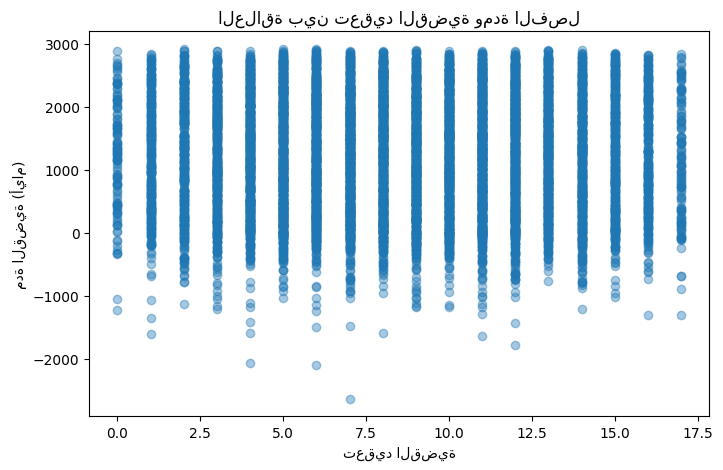

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(
    df["تعقيد_القضية"],
    df["مدة_القضية_بالايام"],
    alpha=0.4
)
plt.xlabel("تعقيد القضية")
plt.ylabel("مدة القضية (أيام)")
plt.title("العلاقة بين تعقيد القضية ومدة الفصل")
plt.show()


<Axes: ylabel='القاضي'>

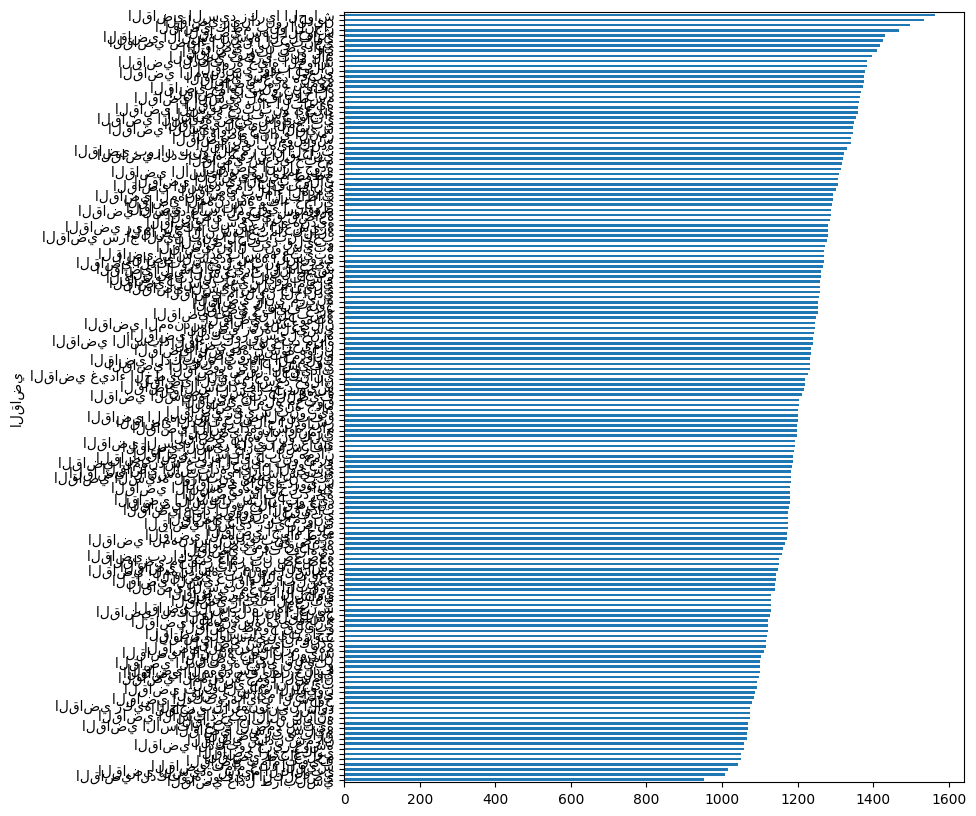

In [ ]:
judge_behavior = (
    df.groupby("القاضي")["مدة_القضية_بالايام"]
    .mean()
    .sort_values()
)

judge_behavior.plot(kind="barh", figsize=(8,10))

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_reg(name, model):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print("="*60)
    print("Model:", name)
    print("MAE :", mean_absolute_error(y_test, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
    print("R2  :", r2_score(y_test, y_pred))

evaluate_reg("Linear Regression", pipe_lr)
evaluate_reg("Random Forest", pipe_rf)
evaluate_reg("Gradient Boosting", pipe_gb)

NameError: name 'pipe_lr' is not defined